In [1]:
!pip install cdsapi netCDF4 cfgrib xarray


In [2]:
import cdsapi
import xarray as xr
import numpy as np
import pandas as pd
from pathlib import Path
import time
import shutil
import os
import time
import calendar
import gc
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

In [3]:
# Check disk space
def check_space():
    total, used, free = shutil.disk_usage(".")
    free_gb = free / (1024**3)
    print(f"Total: {total/(1024**3):.1f} GB")
    print(f"Used: {used/(1024**3):.1f} GB")
    print(f"Free: {free_gb:.1f} GB")
    return free_gb

free_space = check_space()
if free_space < 5:
    print("WARNING: Less than 5GB free!")
else:
    print("Enough space to proceed!")

Total: 19.5 GB
Used: 9.7 GB
Free: 9.8 GB
Enough space to proceed!


In [4]:
# File paths
OCEAN_FILE = Path("final_datasets/subsurface_daily_1993_2025.nc")
ERA5_FILE = Path("final_datasets/era5_DAILY_1993_2025.nc")
OUTPUT_DIR = Path("final_datasets")
OUTPUT_DIR.mkdir(exist_ok=True)

In [5]:
def load_datasets():
    """
    Load ocean and ERA5 datasets with chunking for memory efficiency
    """
    print("Loading datasets...")
    
    if not OCEAN_FILE.exists():
        print(f"Ocean file not found: {OCEAN_FILE}")
        return None, None
    
    if not ERA5_FILE.exists():
        print(f"ERA5 file not found: {ERA5_FILE}")
        return None, None
    
    print(f"   Ocean: {OCEAN_FILE.name}")
    print(f"   ERA5: {ERA5_FILE.name}")
    
    # Load with chunking
    ocean = xr.open_dataset(OCEAN_FILE, chunks={'time': 365})
    era5 = xr.open_dataset(ERA5_FILE, chunks={'time': 365})
    
    print(f"\nLoaded datasets:")
    print(f"Ocean: {len(ocean.time)} days, {len(ocean.longitude)}×{len(ocean.latitude)} grid")
    print(f"     Resolution: {ocean.longitude.values[1] - ocean.longitude.values[0]:.4f}° (~4.2 km)")
    print(f"ERA5:  {len(era5.time)} days, {len(era5.longitude)}×{len(era5.latitude)} grid")
    print(f"     Resolution: {era5.longitude.values[1] - era5.longitude.values[0]:.3f}° (~31 km)")
    
    return ocean, era5

In [6]:
ocean, era5 = load_datasets()

Loading datasets...
   Ocean: subsurface_daily_1993_2025.nc
   ERA5: era5_DAILY_1993_2025.nc

Loaded datasets:
Ocean: 12053 days, 289×144 grid
     Resolution: 0.0417° (~4.2 km)
ERA5:  12053 days, 49×25 grid
     Resolution: 0.250° (~31 km)


In [7]:
def check_time_overlap(ocean, era5):
    """
    Find common time period between ocean and atmosphere data
    """
    print("\nChecking time overlap...")
    
    ocean_start = ocean.time.values[0]
    ocean_end = ocean.time.values[-1]
    era5_start = era5.time.values[0]
    era5_end = era5.time.values[-1]
    
    print(f"   Ocean: {ocean_start} to {ocean_end}")
    print(f"   ERA5:  {era5_start} to {era5_end}")
    
    # Find common period
    common_start = max(ocean_start, era5_start)
    common_end = min(ocean_end, era5_end)
    
    print(f"Common period: {common_start} to {common_end}")
    
    # Select common times
    ocean_subset = ocean.sel(time=slice(common_start, common_end))
    era5_subset = era5.sel(time=slice(common_start, common_end))
    
    print(f"Selected {len(ocean_subset.time)} common days")
    
    return ocean_subset, era5_subset

In [8]:
ocean, era5 = check_time_overlap(ocean, era5)


Checking time overlap...
   Ocean: 1993-01-01T00:00:00.000000000 to 2025-12-31T00:00:00.000000000
   ERA5:  1993-01-01T00:00:00.000000000 to 2025-12-31T00:00:00.000000000
Common period: 1993-01-01T00:00:00.000000000 to 2025-12-31T00:00:00.000000000
Selected 12053 common days


In [11]:
def align_times_exactly(ocean_coarse, era5):
    """
    Ensure both datasets have exactly the same time coordinates
    """
    print("\nAligning times exactly...")
    
    # Get exact common times
    ocean_times = set(ocean_coarse.time.values)
    era5_times = set(era5.time.values)
    common_times = sorted(ocean_times & era5_times)
    
    print(f"   Ocean times: {len(ocean_times)}")
    print(f"   ERA5 times: {len(era5_times)}")
    print(f"   Common times: {len(common_times)}")
    
    if len(common_times) < len(ocean_coarse.time):
        diff = len(ocean_coarse.time) - len(common_times)
        print(f"   Removed {diff} misaligned times")
    
    # Select common times
    ocean_aligned = ocean_coarse.sel(time=common_times)
    era5_aligned = era5.sel(time=common_times)
    
    print(f"   Both datasets aligned to {len(common_times)} times")
    
    return ocean_aligned, era5_aligned



In [12]:
# def sample_era5_to_ocean(era5, ocean):
#     """
#     Extract atmospheric variables exactly at ocean pixels
#     No artificial ocean creation
#     No NaN spreading
#     """
#     print("\nSampling ERA5 onto ocean grid...")

#     era5_on_ocean = era5.interp(
#         latitude=ocean.latitude,
#         longitude=ocean.longitude,
#         method="nearest"  # IMPORTANT
#     )

#     print("ERA5 sampled to ocean grid")
#     print(f"Grid size: {len(ocean.latitude)} x {len(ocean.longitude)}")

#     return era5_on_ocean


In [13]:
def sample_ocean_to_era5(era5, ocean):

    bilin = ocean.interp(
        latitude=era5.latitude,
        longitude=era5.longitude,
        method="linear"
    )

    nearest = ocean.interp(
        latitude=era5.latitude,
        longitude=era5.longitude,
        method="nearest"
    )

    combined = bilin.where(~np.isnan(bilin), nearest)

    return combined


In [14]:
ocean_aligned, era5_aligned = align_times_exactly(ocean, era5)


Aligning times exactly...
   Ocean times: 12053
   ERA5 times: 12053
   Common times: 12053
   Both datasets aligned to 12053 times


In [15]:
# era5_sampled = sample_era5_to_ocean(era5_aligned, ocean_aligned)

In [16]:
ocean_sampled = sample_ocean_to_era5(era5_aligned, ocean_aligned)

In [17]:
combined = xr.merge([era5_aligned, ocean_sampled], join="inner")

In [18]:
ocean_mask = combined['sst'].notnull().any(dim='time')
clean_dataset = combined.where(ocean_mask)

In [19]:
for v in ['sst','temp_0_50m','ohc_0_50m','u10','v10']:
    if v in clean_dataset:
        val = clean_dataset[v].notnull().sum().compute().item()
        print(v, val)


sst 11703463
temp_0_50m 10992336
ohc_0_50m 10992336
u10 11703463
v10 11703463


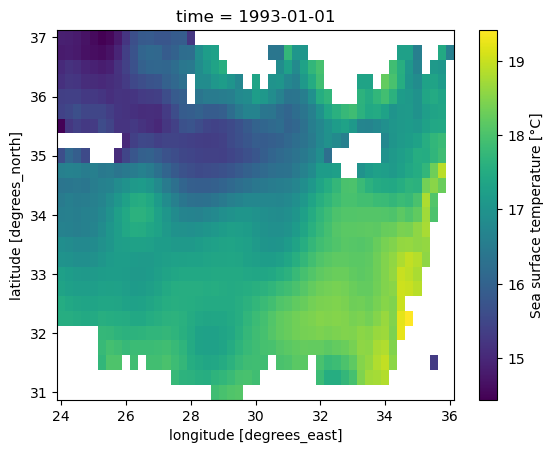

In [22]:
clean_dataset['sst'].isel(time=0).plot()

In [23]:
mask_ocean = clean_dataset['sst'].notnull()
mask_atm   = clean_dataset['u10'].notnull()

overlap = (mask_ocean & mask_atm).mean().compute()

print("Ocean-Atmosphere overlap:", float(overlap)*100, "%")

subsurf = clean_dataset['temp_0_50m'].notnull()
sub_overlap = (mask_ocean & subsurf).mean().compute()

print("Ocean-subsurface and surface overlap:", float(sub_overlap)*100, "%")


Ocean-Atmosphere overlap: 79.26530612244898 %
Ocean-subsurface and surface overlap: 74.44897959183675 %


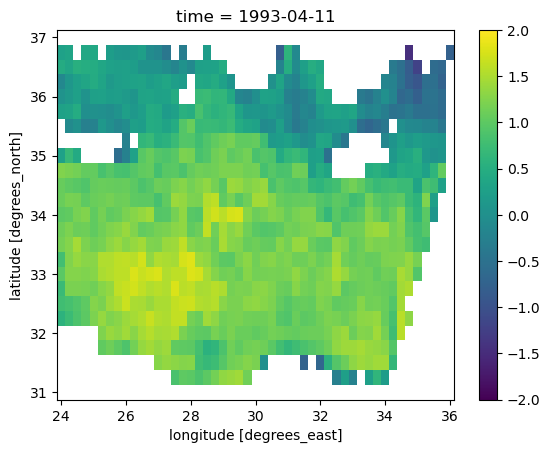

In [24]:
diff = clean_dataset['sst'].isel(time=100) - clean_dataset['temp_0_50m'].isel(time=100)
diff.plot(vmin=-2, vmax=2)


In [25]:
def validate_merged_dataset(combined):
    """
    Validate the merged dataset structure and coverage
    """
    print("\n Validating merged dataset...")
    
    # Check ocean mask
    ocean_mask = combined['temp_0_50m'].isel(time=0).notnull()
    ocean_points = ocean_mask.sum().values
    total_points = ocean_mask.size
    
    print(f"   Grid points:")
    print(f"      Ocean: {ocean_points} ({ocean_points/total_points*100:.1f}%)")
    print(f"      Land: {total_points - ocean_points} ({(total_points-ocean_points)/total_points*100:.1f}%)")
    
    # Check sample location (center of domain - likely ocean)
    sample_lon = combined.longitude.values[len(combined.longitude)//2]
    sample_lat = combined.latitude.values[len(combined.latitude)//2]
    sample = combined.sel(longitude=sample_lon, latitude=sample_lat, time=combined.time[0])
    
    print(f"\n   Sample point ({sample_lat:.1f}°N, {sample_lon:.1f}°E):")
    check_vars = ['temp_0_50m', 'sst', 't2m', 'ssr_flux']
    for var in check_vars:
        if var in sample:
            has_data = not np.isnan(sample[var].values)
            status = 'okay' if has_data else 'not okay'
            print(f"      {status} {var}")
    
    # Overall coverage (sample first timestep to avoid loading all data)
    print(f"\n   Data coverage (first timestep):")
    first_time = combined.isel(time=0)
    for var in combined.data_vars:
        valid_pct = (first_time[var].notnull().sum() / first_time[var].size * 100).values
        print(f"      {var}: {valid_pct:.1f}% valid")
    
    print(f"\n Validation complete")
    
    return True



In [26]:
# Run it
validate_merged_dataset(combined)


 Validating merged dataset...
   Grid points:
      Ocean: 924 (75.4%)
      Land: 301 (24.6%)

   Sample point (34.0°N, 30.0°E):
      okay temp_0_50m
      okay sst
      okay t2m
      okay ssr_flux

   Data coverage (first timestep):
      u10: 100.0% valid
      v10: 100.0% valid
      t2m: 100.0% valid
      msl: 100.0% valid
      sst: 79.3% valid
      wind_speed: 100.0% valid
      ssr_flux: 100.0% valid
      str_flux: 100.0% valid
      sensible_flux: 100.0% valid
      latent_flux: 100.0% valid
      net_heat_flux: 100.0% valid
      temp_0_50m: 75.4% valid
      temp_50_100m: 72.9% valid
      temp_100_150m: 71.3% valid
      ohc_0_50m: 75.4% valid
      ohc_50_100m: 72.9% valid
      ohc_100_150m: 71.3% valid

 Validation complete


True

In [27]:
for var in combined.data_vars:
    print(var, combined[var].dims)


u10 ('time', 'latitude', 'longitude')
v10 ('time', 'latitude', 'longitude')
t2m ('time', 'latitude', 'longitude')
msl ('time', 'latitude', 'longitude')
sst ('time', 'latitude', 'longitude')
wind_speed ('time', 'latitude', 'longitude')
ssr_flux ('time', 'latitude', 'longitude')
str_flux ('time', 'latitude', 'longitude')
sensible_flux ('time', 'latitude', 'longitude')
latent_flux ('time', 'latitude', 'longitude')
net_heat_flux ('time', 'latitude', 'longitude')
temp_0_50m ('time', 'latitude', 'longitude')
temp_50_100m ('time', 'latitude', 'longitude')
temp_100_150m ('time', 'latitude', 'longitude')
ohc_0_50m ('time', 'latitude', 'longitude')
ohc_50_100m ('time', 'latitude', 'longitude')
ohc_100_150m ('time', 'latitude', 'longitude')


In [28]:
def save_combined_dataset(combined):
    """
    Save the merged dataset to disk
    """
    output_file = OUTPUT_DIR / "ocean_atmos_combined_DAILY_1993_2025.nc"
    
    print(f"\nSaving combined dataset...")
    print(f"   File: {output_file}")
    print(f"   (This may take 10-15 minutes...)")
    encoding = {
    var: {
        'zlib': True,
        'complevel': 4,
    }
    for var in combined.data_vars
    }
    combined.to_netcdf(
        output_file,
        mode='w',
        format='NETCDF4',
        engine='netcdf4',
        encoding=encoding
    )
    
    combined.close()
    gc.collect()
    
    size_mb = output_file.stat().st_size / (1024**2)
    
    print(f"Saved successfully!")
    print(f"Size: {size_mb:.0f} MB")
    
    return output_file



In [29]:
# Run it
output_file = save_combined_dataset(combined)


Saving combined dataset...
   File: final_datasets/ocean_atmos_combined_DAILY_1993_2025.nc
   (This may take 10-15 minutes...)
Saved successfully!
Size: 524 MB


In [43]:
def print_final_summary(output_file):
    """
    Print comprehensive summary of the final dataset
    """
    ds = xr.open_dataset(output_file)
    size_mb = output_file.stat().st_size / (1024**2)
    
    print(f"\n{'='*65}")
    print(f"COMBINED DATASET READY!")
    print(f"{'='*65}")
    print(f"File: {output_file}")
    print(f"Size: {size_mb:.0f} MB")
    print(f"Resolution: 0.25° (~31 km)")
    print(f"Domain: {ds.longitude.min().values:.1f}°E to {ds.longitude.max().values:.1f}°E")
    print(f"           {ds.latitude.min().values:.1f}°N to {ds.latitude.max().values:.1f}°N")
    print(f"Grid: {len(ds.longitude)} × {len(ds.latitude)} = {len(ds.longitude) * len(ds.latitude)} points")
    
    print(f"\nTime coverage:")
    print(f"   Start: {ds.time.values[0]}")
    print(f"   End:   {ds.time.values[-1]}")
    print(f"   Days: {len(ds.time)}")
    
    print(f"\nOcean variables:")
    for var in ['temp_0_50m', 'temp_50_100m', 'temp_100_150m','ohc_0_50m', 'ohc_50_100m' , 'ohc_100_150m']:
        if var in ds:
            print(f"   - {var}")
    
    print(f"\nAtmosphere variables:")
    for var in ds.data_vars:
        if var not in ['temp_0_50m', 'temp_50_100m', 'temp_100_150m', 'ohc_0_50m', 'ohc_50_100m' , 'ohc_100_150m']:
            print(f"   - {var}")
    
    print(f"{'='*65}")
    
    ds.close()

In [31]:
OUTPUT_COMBINED = Path("final_datasets/ocean_atmos_combined_DAILY_1993_2025.nc")


In [44]:

print_final_summary(OUTPUT_COMBINED)


COMBINED DATASET READY!
File: final_datasets/ocean_atmos_combined_DAILY_1993_2025.nc
Size: 524 MB
Resolution: 0.25° (~31 km)
Domain: 24.0°E to 36.0°E
           31.0°N to 37.0°N
Grid: 49 × 25 = 1225 points

Time coverage:
   Start: 1993-01-01T00:00:00.000000000
   End:   2025-12-31T00:00:00.000000000
   Days: 12053

Ocean variables:
   - temp_0_50m
   - temp_50_100m
   - temp_100_150m

Atmosphere variables:
   - u10
   - v10
   - t2m
   - msl
   - sst
   - wind_speed
   - ssr_flux
   - str_flux
   - sensible_flux
   - latent_flux
   - net_heat_flux


In [45]:
ds = xr.open_dataset(output_file)

In [47]:
ds.head(20)

<xarray.Dataset> Size: 544kB
Dimensions:        (time: 20, latitude: 20, longitude: 20)
Coordinates:
  * time           (time) datetime64[ns] 160B 1993-01-01 ... 1993-01-20
  * latitude       (latitude) float64 160B 37.0 36.75 36.5 ... 32.75 32.5 32.25
  * longitude      (longitude) float64 160B 24.0 24.25 24.5 ... 28.25 28.5 28.75
Data variables: (12/17)
    u10            (time, latitude, longitude) float32 32kB ...
    v10            (time, latitude, longitude) float32 32kB ...
    t2m            (time, latitude, longitude) float32 32kB ...
    msl            (time, latitude, longitude) float32 32kB ...
    sst            (time, latitude, longitude) float32 32kB ...
    wind_speed     (time, latitude, longitude) float32 32kB ...
    ...             ...
    temp_0_50m     (time, latitude, longitude) float32 32kB ...
    temp_50_100m   (time, latitude, longitude) float32 32kB ...
    temp_100_150m  (time, latitude, longitude) float32 32kB ...
    ohc_0_50m      (time, latitude, longitude) float32 32kB ...
    ohc_50_100m    (time, latitude, longitude) float32 32kB ...
    ohc_100_150m   (time, latitude, longitude) float32 32kB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-01-17T13:27 GRIB to CDM+CF via cfgrib-0.9.1...

# Validate Combined Data

### 1. Check Structure

In [53]:
print(era5_aligned)
print('='*155)
print(ocean_sampled)
print('='*155)
print(combined)


<xarray.Dataset> Size: 650MB
Dimensions:        (time: 12053, latitude: 25, longitude: 49)
Coordinates:
  * time           (time) datetime64[ns] 96kB 1993-01-01 ... 2025-12-31
  * latitude       (latitude) float64 200B 37.0 36.75 36.5 ... 31.5 31.25 31.0
  * longitude      (longitude) float64 392B 24.0 24.25 24.5 ... 35.5 35.75 36.0
Data variables:
    u10            (time, latitude, longitude) float32 59MB dask.array<chunksize=(365, 25, 49), meta=np.ndarray>
    v10            (time, latitude, longitude) float32 59MB dask.array<chunksize=(365, 25, 49), meta=np.ndarray>
    t2m            (time, latitude, longitude) float32 59MB dask.array<chunksize=(365, 25, 49), meta=np.ndarray>
    msl            (time, latitude, longitude) float32 59MB dask.array<chunksize=(365, 25, 49), meta=np.ndarray>
    sst            (time, latitude, longitude) float32 59MB dask.array<chunksize=(365, 25, 49), meta=np.ndarray>
    wind_speed     (time, latitude, longitude) float32 59MB dask.array<chunksize=(36

### 2. Check Missing Data Percentage

In [74]:
for var in combined.data_vars:
    pct = float((combined[var].count() / combined[var].size).compute() * 100)
    print(var, f"{pct:.2f}% valid")


u10 100.00% valid
v10 100.00% valid
t2m 100.00% valid
msl 100.00% valid
sst 79.27% valid
wind_speed 100.00% valid
ssr_flux 100.00% valid
str_flux 100.00% valid
sensible_flux 100.00% valid
latent_flux 100.00% valid
net_heat_flux 100.00% valid
temp_0_50m 75.43% valid
temp_50_100m 72.90% valid
temp_100_150m 71.27% valid
ohc_0_50m 75.43% valid
ohc_50_100m 72.90% valid
ohc_100_150m 71.27% valid


### 3. Check for Constant or Broken Variables

In [75]:
for var in combined.data_vars:
    print(var, float(combined[var].std().compute()))


u10 3.337096929550171
v10 3.3035998344421387
t2m 5.450261116027832
msl 539.4973754882812
sst 4.043673038482666
wind_speed 2.7189903259277344
ssr_flux 79.5172119140625
str_flux 16.82740020751953
sensible_flux 29.042858123779297
latent_flux 72.09648895263672
net_heat_flux 128.53594970703125
temp_0_50m 3.2493488788604736
temp_50_100m 1.485332727432251
temp_100_150m 0.9631484746932983
ohc_0_50m 705684544.0
ohc_50_100m 375053696.0
ohc_100_150m 258553648.0


### 4. Visual Sanity Check 

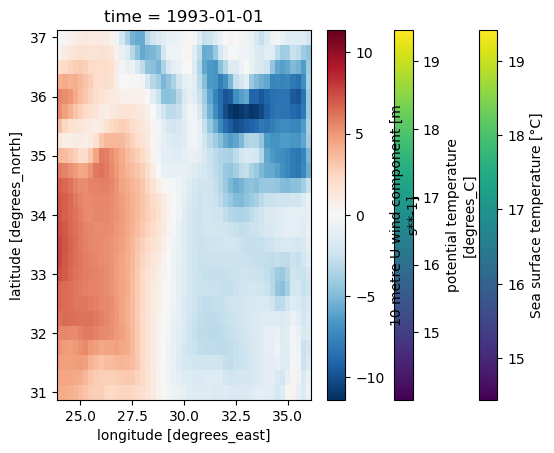

In [76]:
combined['sst'].isel(time=0).plot()
combined['temp_0_50m'].isel(time=0).plot()
combined['u10'].isel(time=0).plot()

 ### 5. Interpolation Quality Check

In [91]:
import matplotlib.pyplot as plt
from scipy.stats import pearsonr


def check_by_viewin_map(vr):
    print("\n\nCheck Map ---------------------------------------------------------")
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    
    native.isel(time=0).plot(ax=ax1)
    ax1.set_title(f"\n{vr} Native (0.08°)")
    
    sampled.isel(time=0).plot(ax=ax2)
    ax2.set_title(f"{vr} Sampled (0.25°)")
    
    plt.show()

def check_MEAN(vr):
    print("\n\nCheck Mean ---------------------------------------------------------")
    print(f"\n{vr} Native Mean : {native.mean().compute().values:.4f}")
    print(f"{vr} Sampled Mean: {sampled.mean().compute().values:.4f}")


def check_STD(vr):
    print("\n\nCheck STD ---------------------------------------------------------")
    print(f"\n{vr} Native Std Dev: {native.std().compute().values:.4f}")
    print(f"{vr} Sampled Std Dev: {sampled.std().compute().values:.4f}")


def check_NAN(vr):
    print("\n\nCheck NAN ---------------------------------------------------------")
    nan_native = native.isnull().sum().compute()
    nan_sampled = sampled.isnull().sum().compute()
    print(f"\n{vr} NaN percentage - Native: {float(nan_native/native.size)*100:.2f}%")
    print(f"{vr} NaN percentage - Sampled: {float(nan_sampled/sampled.size)*100:.2f}%")

def check_Corelation(vr):
    print("\n\nCheck Corelation ---------------------------------------------------------")
    native_mean = native.mean(dim=['latitude', 'longitude']).compute()
    sampled_mean = sampled.mean(dim=['latitude', 'longitude']).compute()
    
    corr, _ = pearsonr(native_mean.values, sampled_mean.values)
    
    print(f"\n{vr} Regional Mean Correlation: {corr:.4f}")


def check_regional_temp(vr):
    print("\n\nCheck Regional Mean  ---------------------------------------------------------")
    native.mean(dim=['latitude', 'longitude']).plot(label='Native', alpha=0.7)
    sampled.mean(dim=['latitude', 'longitude']).plot(label='Sampled', alpha=0.7)
    plt.legend()
    plt.title(f"\n{vr} Regional Mean Time-Series")
    plt.show()






temp_0_50m quality check


Check Map ---------------------------------------------------------


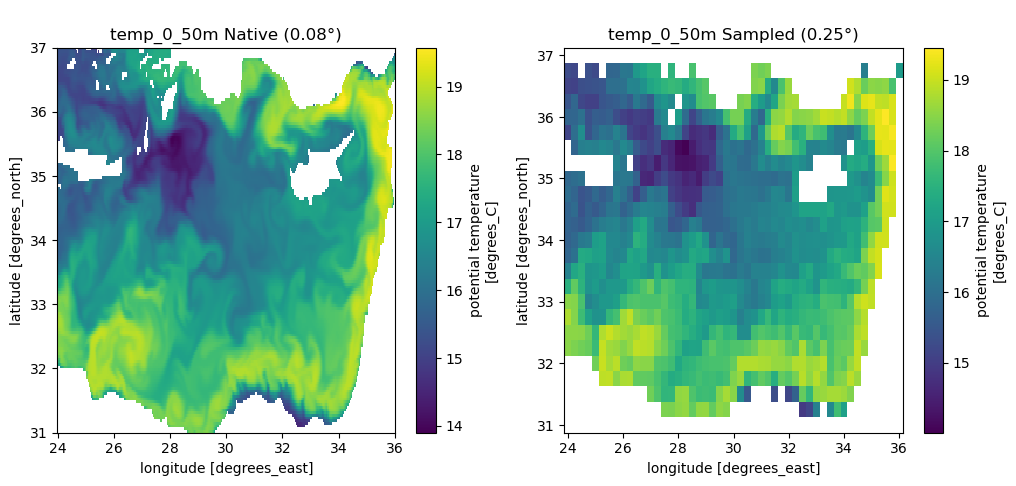



Check Mean ---------------------------------------------------------

temp_0_50m Native Mean : 20.5938
temp_0_50m Sampled Mean: 20.5873


Check STD ---------------------------------------------------------

temp_0_50m Native Std Dev: 3.2597
temp_0_50m Sampled Std Dev: 3.2493


Check NAN ---------------------------------------------------------

temp_0_50m NaN percentage - Native: 19.83%
temp_0_50m NaN percentage - Sampled: 24.57%


Check Corelation ---------------------------------------------------------

temp_0_50m Regional Mean Correlation: 1.0000


Check Regional Mean  ---------------------------------------------------------


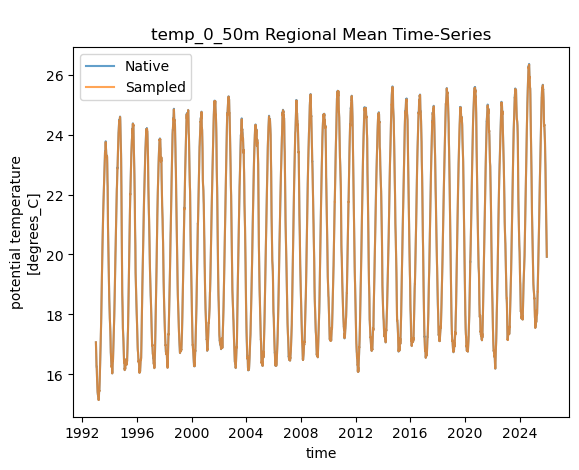





temp_50_100m quality check


Check Map ---------------------------------------------------------


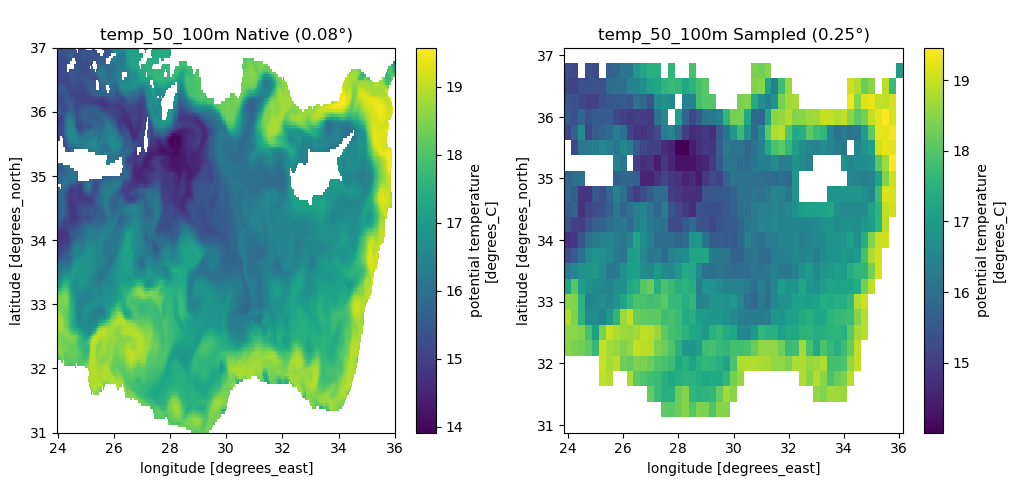



Check Mean ---------------------------------------------------------

temp_50_100m Native Mean : 17.7359
temp_50_100m Sampled Mean: 17.7169


Check STD ---------------------------------------------------------

temp_50_100m Native Std Dev: 1.5168
temp_50_100m Sampled Std Dev: 1.4853


Check NAN ---------------------------------------------------------

temp_50_100m NaN percentage - Native: 22.72%
temp_50_100m NaN percentage - Sampled: 27.10%


Check Corelation ---------------------------------------------------------

temp_50_100m Regional Mean Correlation: 0.9999


Check Regional Mean  ---------------------------------------------------------


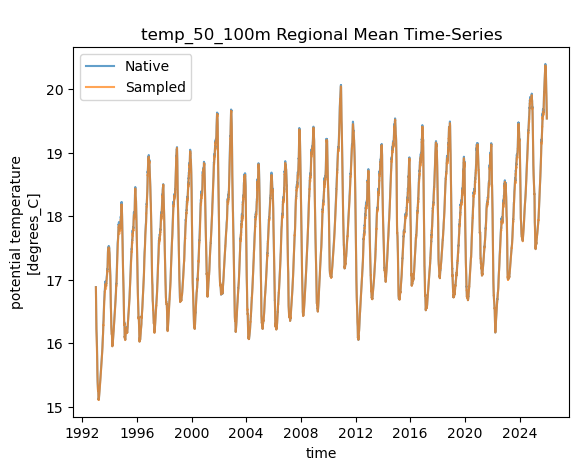





temp_100_150m quality check


Check Map ---------------------------------------------------------


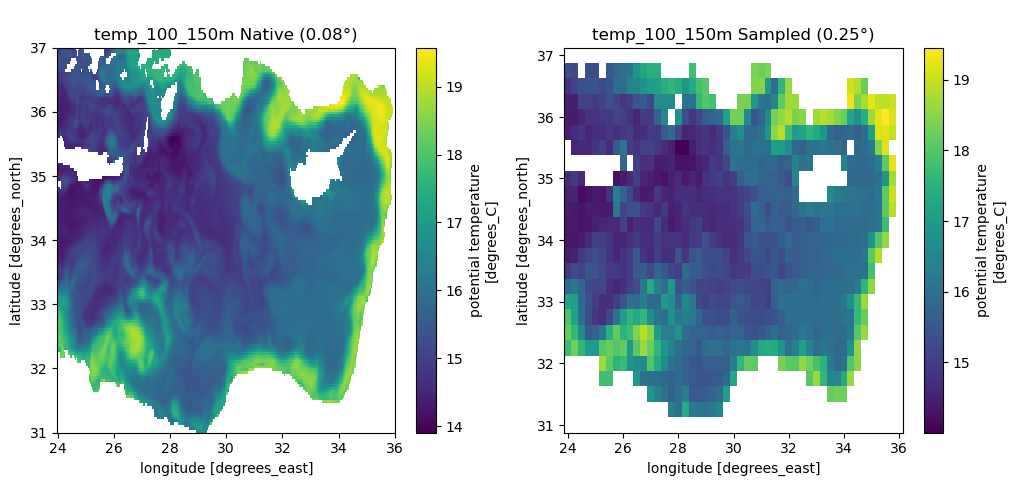



Check Mean ---------------------------------------------------------

temp_100_150m Native Mean : 16.6121
temp_100_150m Sampled Mean: 16.6081


Check STD ---------------------------------------------------------

temp_100_150m Native Std Dev: 0.9646
temp_100_150m Sampled Std Dev: 0.9631


Check NAN ---------------------------------------------------------

temp_100_150m NaN percentage - Native: 25.04%
temp_100_150m NaN percentage - Sampled: 28.73%


Check Corelation ---------------------------------------------------------

temp_100_150m Regional Mean Correlation: 1.0000


Check Regional Mean  ---------------------------------------------------------


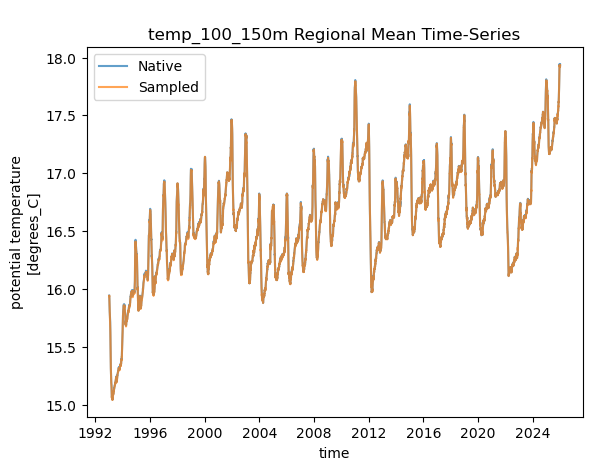





ohc_0_50m quality check


Check Map ---------------------------------------------------------


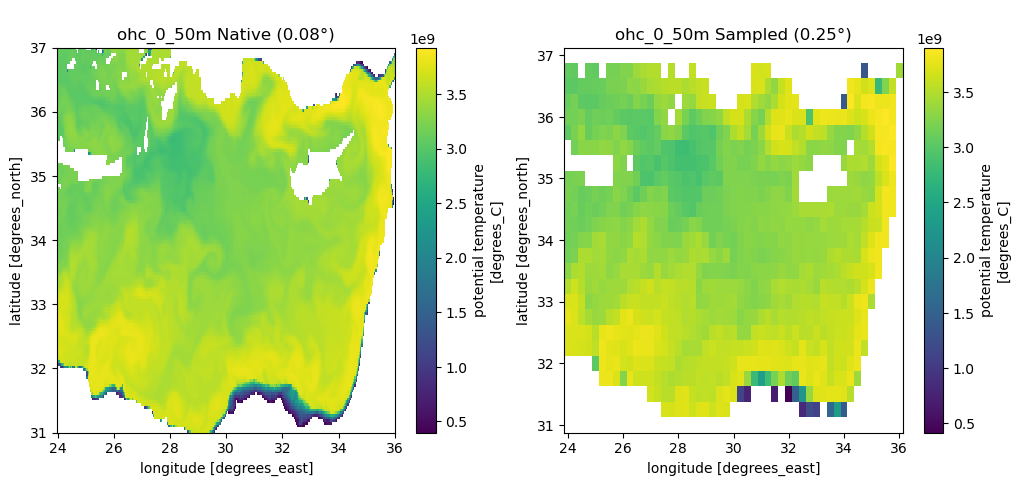



Check Mean ---------------------------------------------------------

ohc_0_50m Native Mean : 4058494464.0000
ohc_0_50m Sampled Mean: 4072314624.0000


Check STD ---------------------------------------------------------

ohc_0_50m Native Std Dev: 730792576.0000
ohc_0_50m Sampled Std Dev: 705684544.0000


Check NAN ---------------------------------------------------------

ohc_0_50m NaN percentage - Native: 19.83%
ohc_0_50m NaN percentage - Sampled: 24.57%


Check Corelation ---------------------------------------------------------

ohc_0_50m Regional Mean Correlation: 1.0000


Check Regional Mean  ---------------------------------------------------------


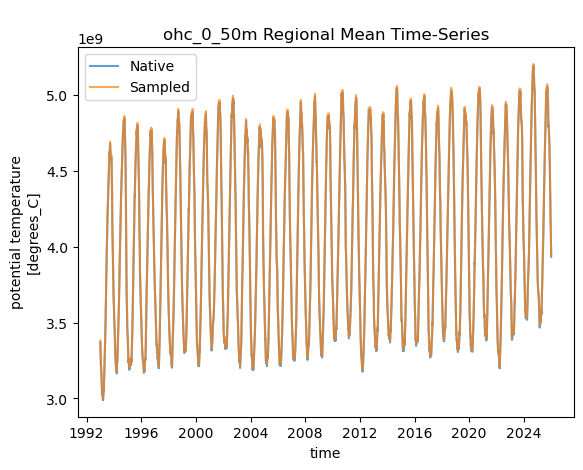





ohc_50_100m quality check


Check Map ---------------------------------------------------------


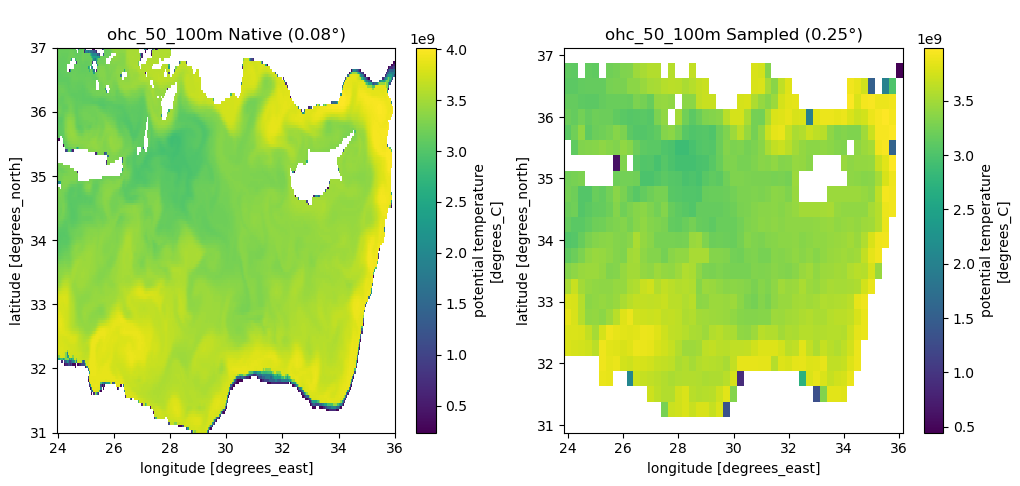



Check Mean ---------------------------------------------------------

ohc_50_100m Native Mean : 3576387072.0000
ohc_50_100m Sampled Mean: 3596446976.0000


Check STD ---------------------------------------------------------

ohc_50_100m Native Std Dev: 440574752.0000
ohc_50_100m Sampled Std Dev: 375053696.0000


Check NAN ---------------------------------------------------------

ohc_50_100m NaN percentage - Native: 22.72%
ohc_50_100m NaN percentage - Sampled: 27.10%


Check Corelation ---------------------------------------------------------

ohc_50_100m Regional Mean Correlation: 1.0000


Check Regional Mean  ---------------------------------------------------------


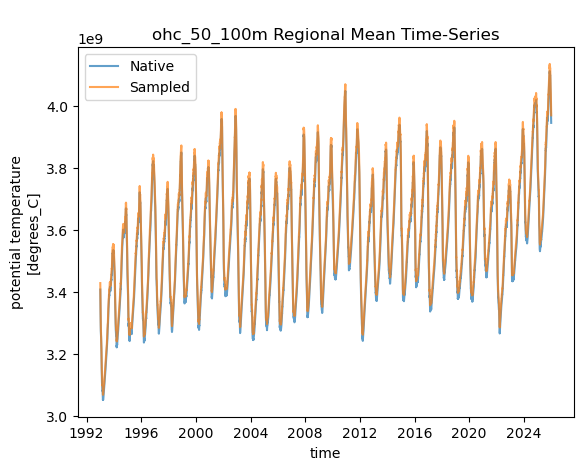





ohc_100_150m quality check


Check Map ---------------------------------------------------------


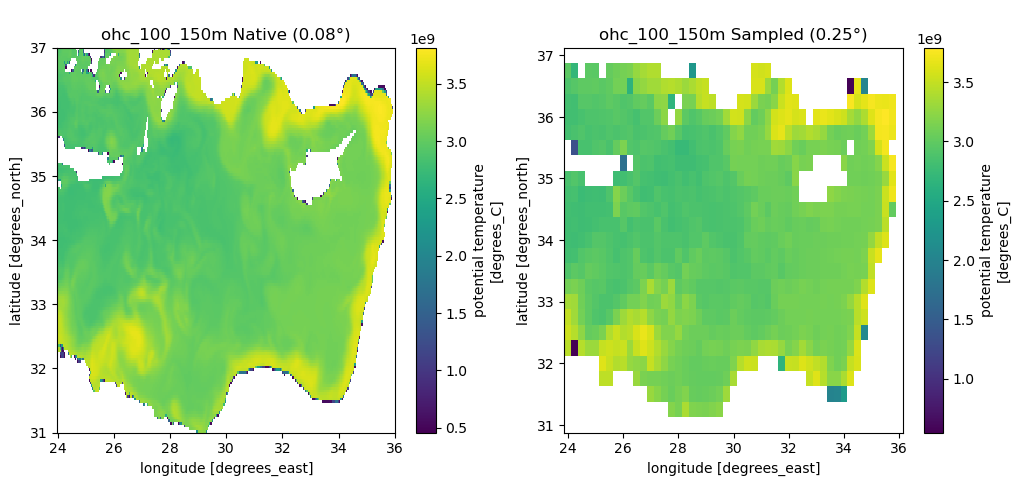



Check Mean ---------------------------------------------------------

ohc_100_150m Native Mean : 3208764672.0000
ohc_100_150m Sampled Mean: 3212931584.0000


Check STD ---------------------------------------------------------

ohc_100_150m Native Std Dev: 294365408.0000
ohc_100_150m Sampled Std Dev: 258553648.0000


Check NAN ---------------------------------------------------------

ohc_100_150m NaN percentage - Native: 25.04%
ohc_100_150m NaN percentage - Sampled: 28.73%


Check Corelation ---------------------------------------------------------

ohc_100_150m Regional Mean Correlation: 1.0000


Check Regional Mean  ---------------------------------------------------------


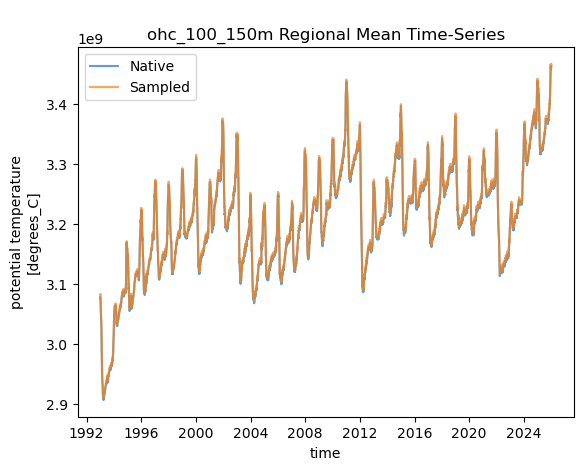

In [92]:
### Mean Temp Check with combine and native
for vr in ['temp_0_50m', 'temp_50_100m', 'temp_100_150m','ohc_0_50m', 'ohc_50_100m' , 'ohc_100_150m']:
    print('\n')
    print('='*155)
    print(f"\n\n{vr} quality check")
    native = ocean_aligned[vr]
    sampled = combined[vr]
    check_by_viewin_map(vr)
    check_MEAN(vr)
    check_STD(vr)
    check_NAN(vr)
    check_Corelation(vr)
    check_regional_temp(vr)

### 6. Check Temporal Continuity

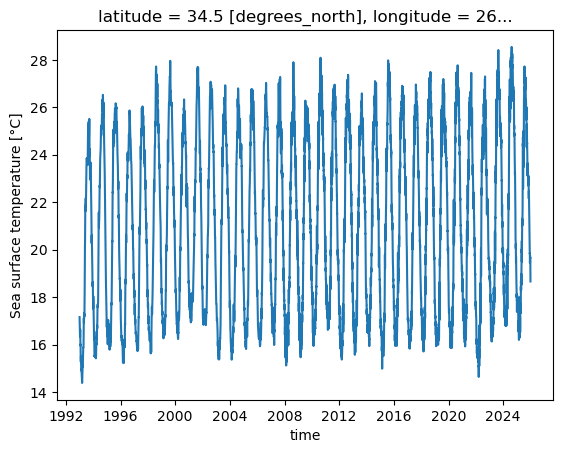

In [57]:
combined['sst'].isel(latitude=10, longitude=10).plot()

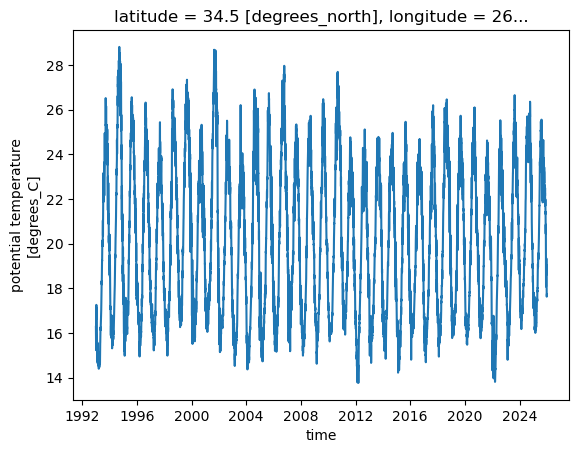

In [58]:
combined['temp_0_50m'].isel(latitude=10, longitude=10).plot()

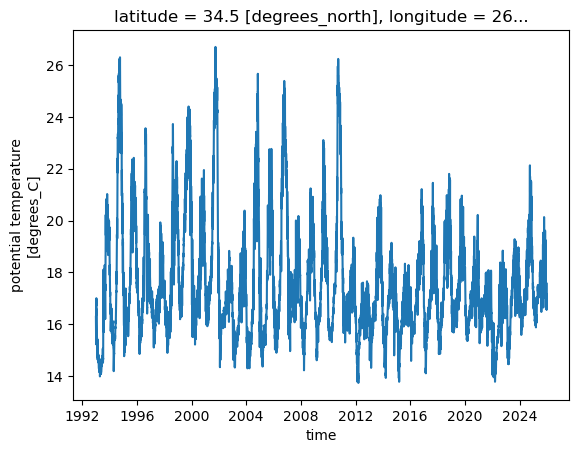

In [59]:
combined['temp_50_100m'].isel(latitude=10, longitude=10).plot()

In [ ]:
# nan_native = native.isnull().sum().compute()
# nan_sampled = sampled.isnull().sum().compute()
# print(f"NaN percentage - Native: {float(nan_native/native.size)*100:.2f}%")
# print(f"NaN percentage - Sampled: {float(nan_sampled/sampled.size)*100:.2f}%")

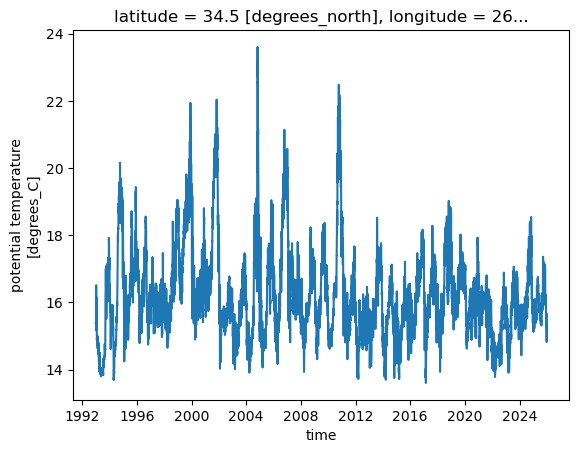

In [60]:
combined['temp_100_150m'].isel(latitude=10, longitude=10).plot()